# Detecção de Anomalias em Transações



## Exploração e Análise do Dataset

A análise inicial identificou 284.807 transações e 31 colunas, sem valores ausentes. A variável `Class` apresenta forte desbalanceamento: 284.315 transações normais (99,8273%) e 492 fraudes (0,1727%), aproximadamente 578 transações normais para cada fraude. Também foram encontradas 1.081 linhas duplicadas, incluindo registros associados às duas classes. Por isso, a acurácia isolada não será suficiente para avaliar os modelos, e o tratamento das duplicatas ainda precisa ser definido antes do treinamento.

In [53]:

import pandas as pd
import numpy as np

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

display(df.head())
# Dimensões da base
print(f"Quantidade de registros: {df.shape[0]:,}")
print(f"Quantidade de colunas: {df.shape[1]}")
df.info()
# Quantidade e percentual de cada classe
distribuicao = df["Class"].value_counts().sort_index()

resumo_classes = pd.DataFrame({
    "Quantidade": distribuicao,
    "Percentual (%)": df["Class"].value_counts(
        normalize=True
    ).sort_index() * 100
})

resumo_classes.index = ["Normal (0)", "Fraude (1)"]
display(resumo_classes.round(4))

# Proporção entre transações normais e fraudulentas
total_normais = (df["Class"] == 0).sum()
total_fraudes = (df["Class"] == 1).sum()

print(f"Transações normais: {total_normais:,}")
print(f"Transações fraudulentas: {total_fraudes:,}")
print(f"Relação normal/fraude: {total_normais / total_fraudes:.1f}:1")

# Verificação de duplicatas
print(f"\nLinhas duplicadas: {df.duplicated().sum():,}")


# Quantidade de duplicatas por classe
duplicatas = df[df.duplicated(keep=False)]

display(
    duplicatas.groupby("Class")
    .agg(
        Registros=("Class", "size"),
        Transacoes=("Class", "count")
    )
)

# Distribuição das classes entre as linhas duplicadas
display(
    duplicatas["Class"]
    .value_counts()
    .rename(index={0: "Normal (0)", 1: "Fraude (1)"})
    .to_frame("Quantidade de linhas duplicadas")
)

# Visualizar alguns exemplos
display(duplicatas.sort_values("Time").head(10))



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Quantidade de registros: 284,807
Quantidade de colunas: 31
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  fl

,Quantidade,Percentual (%)
Normal (0),284315,99.8273
Fraude (1),492,0.1727


Transações normais: 284,315
Transações fraudulentas: 492
Relação normal/fraude: 577.9:1

Linhas duplicadas: 1,081


,Registros,Transacoes
Class,,
0,1822,1822
1,32,32


,Quantidade de linhas duplicadas
Class,
Normal (0),1822
Fraude (1),32


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
222,145.0,-2.419486,1.949346,0.552998,0.982710,-0.284815,2.411200,-1.398537,-0.188922,0.675695,...,1.213390,-1.238354,0.007191,-1.724175,0.239721,-0.313607,-0.187431,0.119472,6.74,0


## Medindo o impactado da remoção das duplicatas

A remoção das 1.081 linhas duplicadas reduziu a base de 284.807 para 283.726 registros. Desse total, 19 fraudes foram removidas, reduzindo a quantidade de 492 para 473 casos. Consequentemente, a proporção de fraudes caiu de 0,1727% para 0,1667%, agravando ligeiramente o desbalanceamento. Esses resultados mostram que a remoção de duplicatas afeta diretamente a classe minoritária, por isso, seguiremos com a base original dos dados

In [54]:

# Quantidade de registros antes da remoção
print(f"Registros originais: {len(df):,}")

# Simulação: remover duplicatas exatas, preservando a primeira ocorrência
df_sem_duplicatas = df.drop_duplicates()

print(f"Registros após remoção: {len(df_sem_duplicatas):,}")
print(f"Registros removidos: {len(df) - len(df_sem_duplicatas):,}")

# Comparar a quantidade de fraudes antes e depois
comparacao = pd.DataFrame({
    "Antes": df["Class"].value_counts().sort_index(),
    "Depois": df_sem_duplicatas["Class"].value_counts().sort_index()
}).fillna(0).astype(int)

comparacao.index = ["Normal (0)", "Fraude (1)"]

display(comparacao)

# Comparar a proporção de fraudes
print(
    f"Percentual de fraudes antes: "
    f"{df['Class'].mean() * 100:.4f}%"
)

print(
    f"Percentual de fraudes depois: "
    f"{df_sem_duplicatas['Class'].mean() * 100:.4f}%"
)


Registros originais: 284,807
Registros após remoção: 283,726
Registros removidos: 1,081


,Antes,Depois
Normal (0),284315,283253
Fraude (1),492,473


Percentual de fraudes antes: 0.1727%
Percentual de fraudes depois: 0.1667%


## Análise da variávels

Realizando a análise exploratória dos dados (EDA), investigando o desbalanceamento das classes, as duplicatas e as variáveis Amount, Time e suas correlações com a ocorrência de fraudes. Identificamos que as transações fraudulentas apresentam média de valor maior, mas mediana menor que as normais, além de diferenças na distribuição temporal. As variáveis V17, V14 e V12 tiveram as maiores correlações negativas com a classe, enquanto V11, V4 e V2 apresentaram as maiores positivas. Concluímos que o conjunto é extremamente desbalanceado e que nenhuma variável isolada é suficiente para identificar fraudes, reforçando a necessidade de construir e avaliar modelos de classificação

### Amount

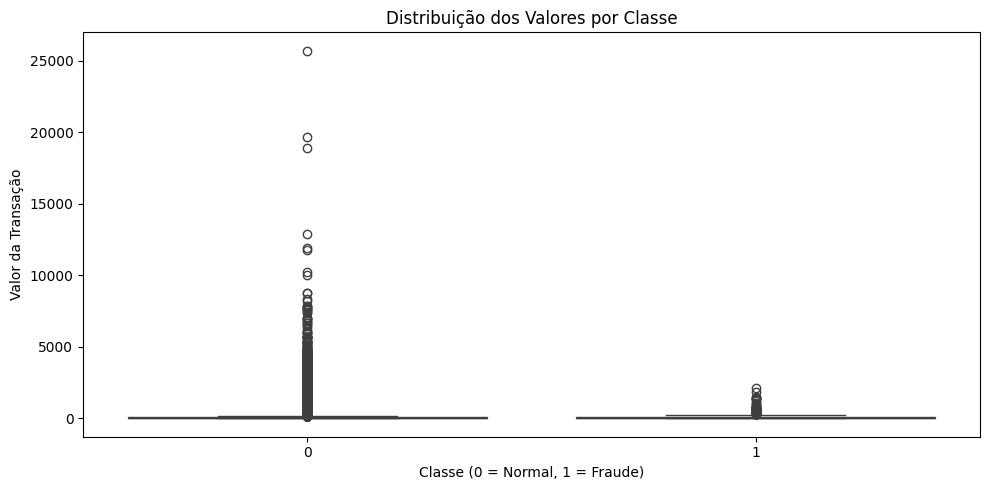

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

df.groupby('Class')['Amount'].describe()

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Class', y='Amount')

plt.title('Distribuição dos Valores por Classe')
plt.xlabel('Classe (0 = Normal, 1 = Fraude)')
plt.ylabel('Valor da Transação')
plt.tight_layout()
plt.show()

### Time

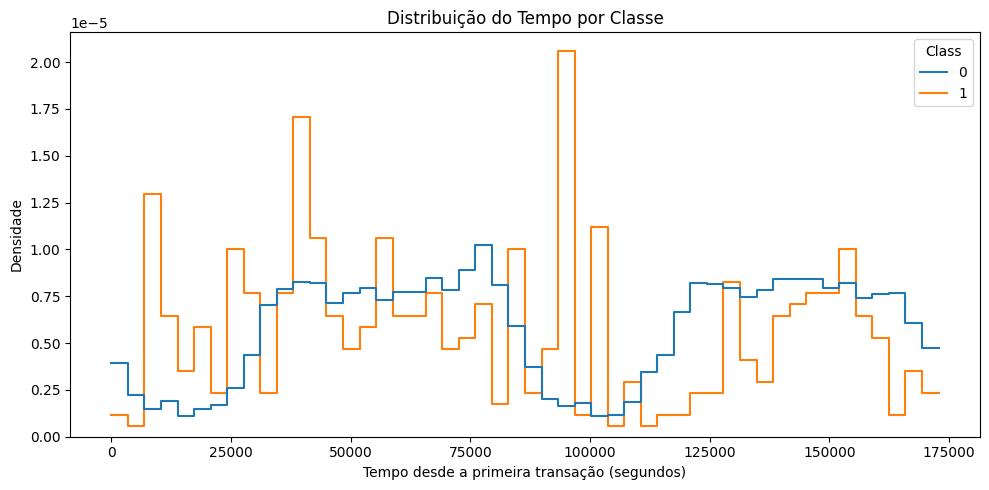

In [56]:
df.groupby('Class')['Time'].describe()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Time',
    hue='Class',
    bins=50,
    stat='density',
    common_norm=False,
    element='step',
    fill=False
)

plt.title('Distribuição do Tempo por Classe')
plt.xlabel('Tempo desde a primeira transação (segundos)')
plt.ylabel('Densidade')
plt.tight_layout()
plt.show()

### Relação entre **Amount** e **Time**

In [57]:
# Correlação das variáveis com a classe
correlacoes = (
    df.corr(numeric_only=True)['Class']
    .drop('Class')
    .sort_values()
)

display(correlacoes.to_frame(name='Correlacao com Class'))

,Correlacao com Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


###

## Preparação dos dados e divisão entre treino e teste

- Treino: 227.845 registros, incluindo 394 fraudes.
- Teste: 56.962 registros, incluindo 98 fraudes.
- Proporção de fraudes: aproximadamente 0,173% em ambos os conjuntos.

Apesar da divisão correta, o desbalanceamento permanece: o modelo terá muito mais exemplos de transações normais do que fraudulentas. Por isso, a acurácia isolada não será suficiente para avaliar seu desempenho.

### Engenharia de Features: Transformação Logarítmica de `Amount`
Como a variável `Amount` possui valores discrepantes com uma distribuição de cauda muito longa, aplicaremos a transformação `log(x + 1)` usando `np.log1p` para aproximar os dados de uma distribuição normal e ajudar os modelos a convergirem melhor.

In [58]:
import numpy as np

# Criando a nova feature Log_Amount
df['Log_Amount'] = np.log1p(df['Amount'])

# Visualizando as estatísticas descritivas para comparar a coluna original e a transformada
display(df[['Amount', 'Log_Amount']].describe())

,Amount,Log_Amount
count,284807.000000,284807.000000
mean,88.349619,3.152188
std,250.120109,1.656648
min,0.000000,0.000000
25%,5.600000,1.887070
50%,22.000000,3.135494
75%,77.165000,4.358822
max,25691.160000,10.153941


### Nova Divisão de Treino e Teste
Agora que criamos a feature transformada, atualizaremos as matrizes `X_train` e `X_test` excluindo a coluna `Amount` original para evitar problemas de colinearidade.

In [59]:
from sklearn.model_selection import train_test_split

# O target continua sendo 'Class' e removemos a coluna original 'Amount'
X = df.drop(columns=['Class', 'Amount'])
y = df['Class']

# Nova divisão estratificada com base nos novos atributos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Treino: {X_train.shape}")
print(f"Teste: {X_test.shape}")

Treino: (227845, 30)
Teste: (56962, 30)


In [60]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição no treino:")
display(y_train.value_counts().to_frame(name='Quantidade'))

print("\nDistribuição no teste:")
display(y_test.value_counts().to_frame(name='Quantidade'))

Treino: (227845, 31)
Teste: (56962, 31)

Distribuição no treino:


,Quantidade
Class,
0,227451
1,394



Distribuição no teste:


,Quantidade
Class,
0,56864
1,98


## Modelo baseline

O baseline apresentou um resultado interessante: apesar da acurácia de 99,91%, o modelo identificou apenas 63,27% das fraudes existentes. Isso mostra por que não podemos avaliar esse problema apenas pela acurácia.
Análise dos resultados
- Precision (82,67%): das transações classificadas como fraude, aproximadamente 83% eram realmente fraudulentas.
- Recall (63,27%): o modelo identificou 62 das 98 fraudes, deixando passar 36.
- F1-score (71,68%): representa o equilíbrio entre precision e recall para a classe de fraude.
- Acurácia (99,91%): é elevada, mas sofre influência da predominância de transações normais.

O modelo é relativamente preciso quando sinaliza uma fraude, mas ainda deixa passar cerca de 36,7% das fraudes. Em um sistema de detecção, isso merece atenção.

In [61]:
# Modelo

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(random_state=42, max_iter=1000))
])

modelo_baseline.fit(X_train, y_train)

y_pred = modelo_baseline.predict(X_test)

              precision    recall  f1-score   support

      Normal     0.9994    0.9998    0.9996     56864
      Fraude     0.8312    0.6531    0.7314        98

    accuracy                         0.9992     56962
   macro avg     0.9153    0.8264    0.8655     56962
weighted avg     0.9991    0.9992    0.9991     56962



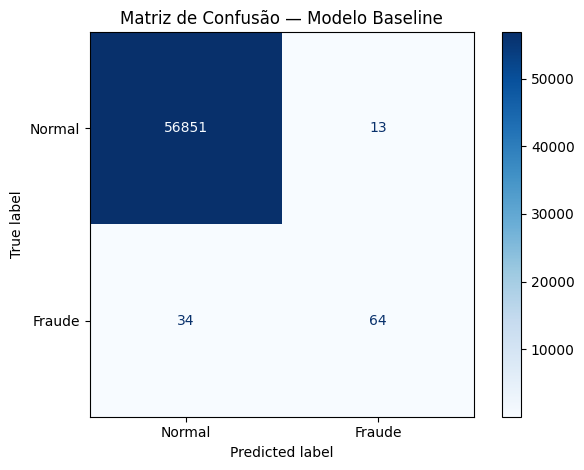

In [62]:
# Análise

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Relatório de classificação
print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal', 'Fraude'],
    digits=4
))

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Fraude']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusão — Modelo Baseline')
plt.tight_layout()
plt.show()

In [63]:
modelo_balanceado = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

modelo_balanceado.fit(X_train, y_train)

y_pred_balanceado = modelo_balanceado.predict(X_test)

print(classification_report(
    y_test,
    y_pred_balanceado,
    target_names=['Normal', 'Fraude'],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9999    0.9757    0.9876     56864
      Fraude     0.0612    0.9184    0.1147        98

    accuracy                         0.9756     56962
   macro avg     0.5305    0.9470    0.5512     56962
weighted avg     0.9982    0.9756    0.9861     56962



## Tratando o desbalanceamento

### Aplicação de Técnicas de Balanceamento
Nesta etapa, criamos duas variantes de treino usando a biblioteca `imbalanced-learn`:
1. **Undersampling (Subamostragem)** com `RandomUnderSampler`.
2. **Oversampling (Superamostragem)** com `SMOTE`.

Ambos serão aplicados sobre as features atualizadas que contêm `Log_Amount` em vez do `Amount` original.

In [64]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# 1. Undersampling
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

# 2. Oversampling (SMOTE)
smote = SMOTE(random_state=42)
X_train_over, y_train_over = smote.fit_resample(X_train, y_train)

# Exibindo a nova distribuição das classes
print("--- Distribuição com Undersampling ---")
print(y_train_under.value_counts())

print("\n--- Distribuição com SMOTE (Oversampling) ---")
print(y_train_over.value_counts())

--- Distribuição com Undersampling ---
Class
0    394
1    394
Name: count, dtype: int64

--- Distribuição com SMOTE (Oversampling) ---
Class
0    227451
1    227451
Name: count, dtype: int64


### Treinamento de Regressão Logística com Dados Balanceados
Vamos treinar o modelo de Regressão Logística nas duas abordagens de amostragem criadas para avaliar o impacto do balanceamento de dados comparado ao modelo original.

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# 1. Regressão Logística com Undersampling
modelo_under = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(random_state=42, max_iter=1000))
])
modelo_under.fit(X_train_under, y_train_under)
y_pred_under = modelo_under.predict(X_test)

# 2. Regressão Logística com SMOTE (Oversampling)
modelo_over = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(random_state=42, max_iter=1000))
])
modelo_over.fit(X_train_over, y_train_over)
y_pred_over = modelo_over.predict(X_test)

print("=== RELATÓRIO DE CLASSIFICAÇÃO: UNDERSAMPLING ===")
print(classification_report(y_test, y_pred_under, target_names=['Normal', 'Fraude'], digits=4))

print("\n=== RELATÓRIO DE CLASSIFICAÇÃO: SMOTE (OVERSAMPLING) ===")
print(classification_report(y_test, y_pred_over, target_names=['Normal', 'Fraude'], digits=4))

=== RELATÓRIO DE CLASSIFICAÇÃO: UNDERSAMPLING ===
              precision    recall  f1-score   support

      Normal     0.9999    0.9698    0.9846     56864
      Fraude     0.0498    0.9184    0.0944        98

    accuracy                         0.9697     56962
   macro avg     0.5248    0.9441    0.5395     56962
weighted avg     0.9982    0.9697    0.9831     56962


=== RELATÓRIO DE CLASSIFICAÇÃO: SMOTE (OVERSAMPLING) ===
              precision    recall  f1-score   support

      Normal     0.9998    0.9899    0.9948     56864
      Fraude     0.1329    0.8980    0.2316        98

    accuracy                         0.9897     56962
   macro avg     0.5664    0.9439    0.6132     56962
weighted avg     0.9983    0.9897    0.9935     56962



### Análise Comparativa dos Resultados de Balanceamento
Agora que os modelos foram treinados, podemos avaliar o desempenho de cada técnica usando o relatório de classificação no conjunto de teste. O foco principal é aumentar o Recall de fraudes sem degradar excessivamente a Precisão.

In [66]:
# Armazenando os resultados para posterior comparação visual e tabelada
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

metricas = {}

for nome, pred in [('Undersampling', y_pred_under), ('SMOTE', y_pred_over)]:
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, beta=1.0, average='binary')
    metricas[nome] = {
        'Precisão (Fraude)': f"{prec:.4f}",
        'Recall (Fraude)': f"{rec:.4f}",
        'F1-Score (Fraude)': f"{f1:.4f}"
    }

display(pd.DataFrame(metricas).T)

,Precisão (Fraude),Recall (Fraude),F1-Score (Fraude)
Undersampling,0.0498,0.9184,0.0944
SMOTE,0.1329,0.8980,0.2316


## Classificadores Avançados (Ensembles)

Agora que estabelecemos nossos baselines com Regressão Logística, vamos elevar o nível da modelagem utilizando algoritmos robustos baseados em árvores que lidam excepcionalmente bem com dados tabulares:

1. **Random Forest Classifier**: Utilizando o hiperparâmetro `class_weight='balanced'` para lidar nativamente com o desbalanceamento.
2. **XGBoost Classifier**: Configurando o parâmetro `scale_pos_weight` para ajustar o custo dos erros na classe minoritária.

In [67]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, precision_recall_fscore_support

# 1. Random Forest com Pesos de Classe
print("Treinando Random Forest (isso pode levar alguns instantes)... ")
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 2. XGBoost com ajuste de peso da classe positiva
# scale_pos_weight é comumente definido como sum(negativas) / sum(positivas)
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()

print("Treinando XGBoost... ")
xgb_model = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=peso_pos,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# Exibindo os relatórios
print("\n=== RELATÓRIO DE CLASSIFICAÇÃO: RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf, target_names=['Normal', 'Fraude'], digits=4))

print("\n=== RELATÓRIO DE CLASSIFICAÇÃO: XGBOOST ===")
print(classification_report(y_test, y_pred_xgb, target_names=['Normal', 'Fraude'], digits=4))

Treinando Random Forest (isso pode levar alguns instantes)... 
Treinando XGBoost... 

=== RELATÓRIO DE CLASSIFICAÇÃO: RANDOM FOREST ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56864
      Fraude     0.9610    0.7551    0.8457        98

    accuracy                         0.9995     56962
   macro avg     0.9803    0.8775    0.9227     56962
weighted avg     0.9995    0.9995    0.9995     56962


=== RELATÓRIO DE CLASSIFICAÇÃO: XGBOOST ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9997     56864
      Fraude     0.8710    0.8265    0.8482        98

    accuracy                         0.9995     56962
   macro avg     0.9353    0.9132    0.9240     56962
weighted avg     0.9995    0.9995    0.9995     56962



### Atualização do Quadro Comparativo Geral
Vamos adicionar os resultados obtidos com Random Forest e XGBoost à nossa tabela consolidada de métricas para avaliar qual abordagem apresenta o melhor trade-off entre Precisão e Recall.

In [68]:
# Adicionando novos modelos ao dicionário de métricas
for nome, pred in [('Random Forest (Balanced)', y_pred_rf), ('XGBoost (Weighted)', y_pred_xgb)]:
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, beta=1.0, average='binary')
    metricas[nome] = {
        'Precisão (Fraude)': f"{prec:.4f}",
        'Recall (Fraude)': f"{rec:.4f}",
        'F1-Score (Fraude)': f"{f1:.4f}"
    }

display(pd.DataFrame(metricas).T)

,Precisão (Fraude),Recall (Fraude),F1-Score (Fraude)
Undersampling,0.0498,0.9184,0.0944
SMOTE,0.1329,0.8980,0.2316
Random Forest (Balanced),0.9610,0.7551,0.8457
XGBoost (Weighted),0.8710,0.8265,0.8482


## Ajuste de Limiar (Threshold Tuning) com Curva Precision-Recall

Em problemas com extremo desbalanceamento, os classificadores vêm configurados por padrão para tomar decisões usando um limiar (*threshold*) de `0.5`. No entanto, muitas vezes é possível aceitar uma leve queda na Precisão em troca de um ganho expressivo no Recall (reduzindo prejuízos financeiros por fraudes não detectadas).

Vamos gerar a Curva Precision-Recall para o **XGBoost** e a **Random Forest** para analisar as escolhas de limiares possíveis.

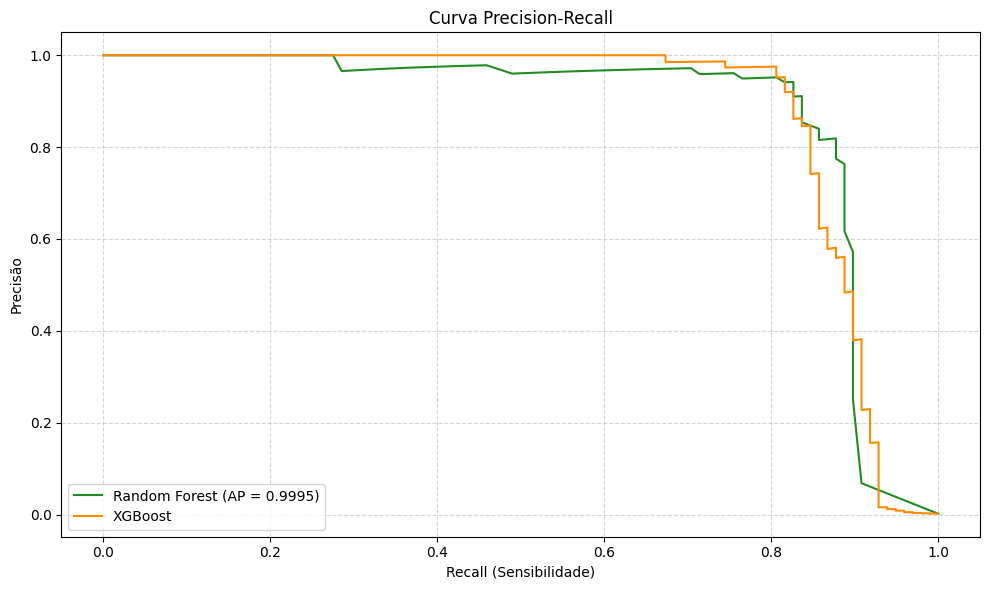

In [69]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Obter as probabilidades para a classe positiva (Fraude)
y_scores_rf = rf_model.predict_proba(X_test)[:, 1]
y_scores_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calcular precision e recall para diferentes limiares
prec_rf, rec_rf, thresholds_rf = precision_recall_curve(y_test, y_scores_rf)
prec_xgb, rec_xgb, thresholds_xgb = precision_recall_curve(y_test, y_scores_xgb)

# Plotar as curvas
plt.figure(figsize=(10, 6))
plt.plot(rec_rf, prec_rf, label=f'Random Forest (AP = {rf_model.score(X_test, y_test):.4f})', color='forestgreen')
plt.plot(rec_xgb, prec_xgb, label='XGBoost', color='darkorange')

plt.title('Curva Precision-Recall')
plt.xlabel('Recall (Sensibilidade)')
plt.ylabel('Precisão')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Simulação de Novos Limiares para o XGBoost

Como o XGBoost se mostrou o modelo mais equilibrado, vamos analisar seu desempenho caso alteremos o limiar padrão de `0.5` para `0.3` ou `0.2`.

In [70]:
import numpy as np
from sklearn.metrics import classification_report

# Testando diferentes limites de corte para o XGBoost
for limiar in [0.2, 0.3, 0.5, 0.7]:
    y_pred_custom = (y_scores_xgb >= limiar).astype(int)
    print(f"\n=== XGBOOST COM LIMIAR DE DECISÃO = {limiar} ===")
    print(classification_report(y_test, y_pred_custom, target_names=['Normal', 'Fraude'], digits=4))


=== XGBOOST COM LIMIAR DE DECISÃO = 0.2 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56864
      Fraude     0.8218    0.8469    0.8342        98

    accuracy                         0.9994     56962
   macro avg     0.9108    0.9233    0.9169     56962
weighted avg     0.9994    0.9994    0.9994     56962


=== XGBOOST COM LIMIAR DE DECISÃO = 0.3 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56864
      Fraude     0.8384    0.8469    0.8426        98

    accuracy                         0.9995     56962
   macro avg     0.9191    0.9233    0.9212     56962
weighted avg     0.9995    0.9995    0.9995     56962


=== XGBOOST COM LIMIAR DE DECISÃO = 0.5 ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9997     56864
      Fraude     0.8710    0.8265    0.8482        98

    accuracy                         0.9995    

## Explicabilidade e Interpretabilidade do Modelo

Nesta última etapa da trilha técnica, analisaremos o comportamento interno do nosso melhor modelo (**XGBoost**). Em sistemas de detecção de fraude, entender o *porquê* de uma transação ter sido classificada como suspeita é essencial para analistas humanos e auditorias.

Faremos isso usando:
1. A importância nativa de variáveis do XGBoost.
2. Valores **SHAP** para uma interpretação mais robusta e matemática das contribuições de cada variável.

In [71]:
# Instalação do SHAP
!pip install -q shap

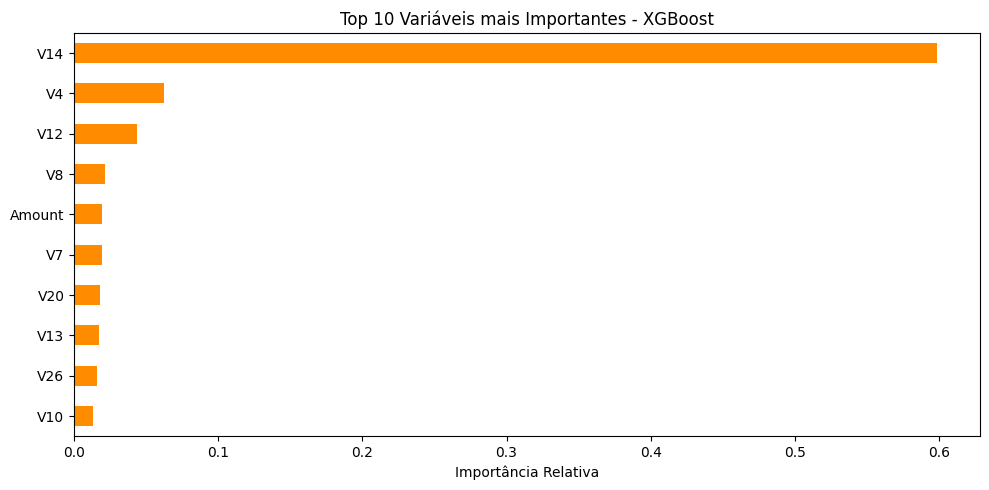

Calculando valores SHAP (isso pode levar alguns instantes)... 


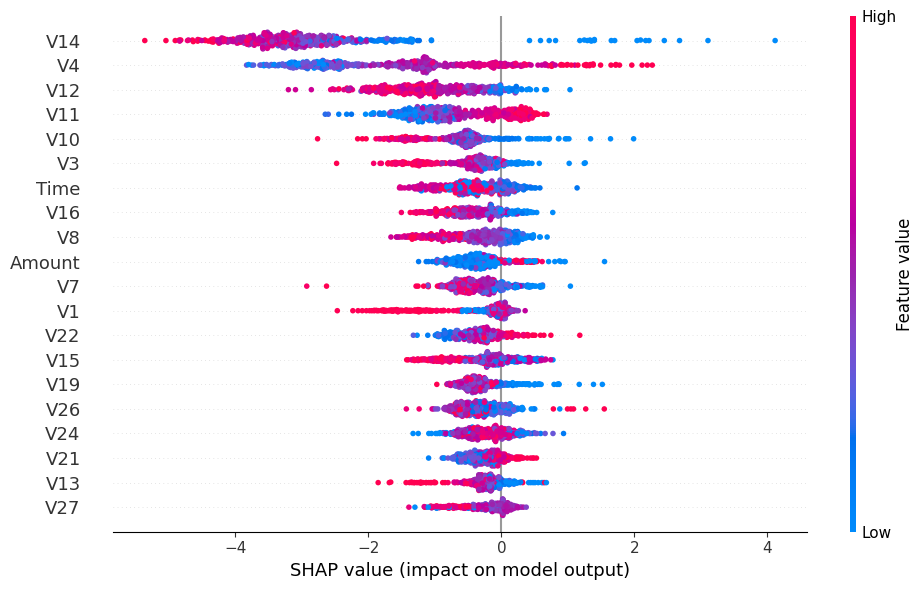

In [72]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

# 1. Feature Importance Nativa
importancias = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
importancias_ordenadas = importancias.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
importancias_ordenadas.plot(kind='barh', color='darkorange')
plt.gca().invert_yaxis()
plt.title('Top 10 Variáveis mais Importantes - XGBoost')
plt.xlabel('Importância Relativa')
plt.tight_layout()
plt.show()

# 2. Explicabilidade com SHAP
print("Calculando valores SHAP (isso pode levar alguns instantes)... ")
explainer = shap.TreeExplainer(xgb_model)
# Calculando para uma amostra de teste para otimizar velocidade de processamento
shap_values = explainer(X_test.head(500))

# Plot Summary do SHAP
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test.head(500), plot_size=(10, 6))
plt.show()